<a href="https://colab.research.google.com/github/srirammulukuntla11/AIEC/blob/main/aiec_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MADALINE HEART DISEASE CLASSIFICATION SYSTEM

Original Dataset Shape: (303, 14)

First 5 Records:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Dataset Shape After Removing Mis

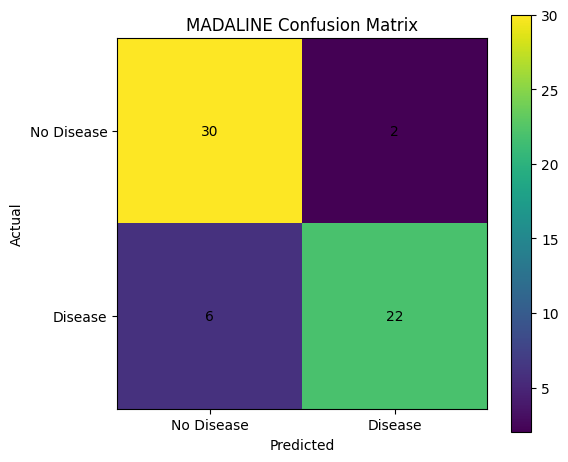

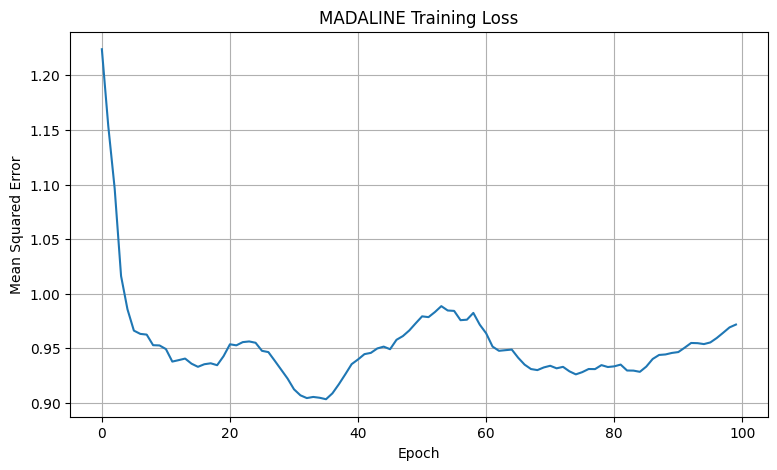


ADAPTIVE LEARNING RATE ANALYSIS

Testing Learning Rate: 0.0001

Testing Learning Rate: 0.0005

Testing Learning Rate: 0.001

Testing Learning Rate: 0.005

Testing Learning Rate: 0.01

Learning Rate Results:
 Learning Rate  Accuracy (%)  Final Loss
        0.0001     76.666667    0.948020
        0.0005     80.000000    0.982954
        0.0010     83.333333    0.973406
        0.0050     73.333333    0.943756
        0.0100     76.666667    0.876713

Best Learning Rate: 0.001
Best Accuracy: 83.33%

ADAPTIVE DECISION ANALYSIS
     Actual Label Predicted Label  Decision Score
0      No Disease      No Disease       -0.048494
1      No Disease      No Disease       -0.002753
2      No Disease   Heart Disease        0.018483
3      No Disease      No Disease       -0.002055
4      No Disease      No Disease       -0.000399
5      No Disease      No Disease       -0.032605
6   Heart Disease   Heart Disease        0.007028
7      No Disease      No Disease       -0.046481
8   Heart Disease  

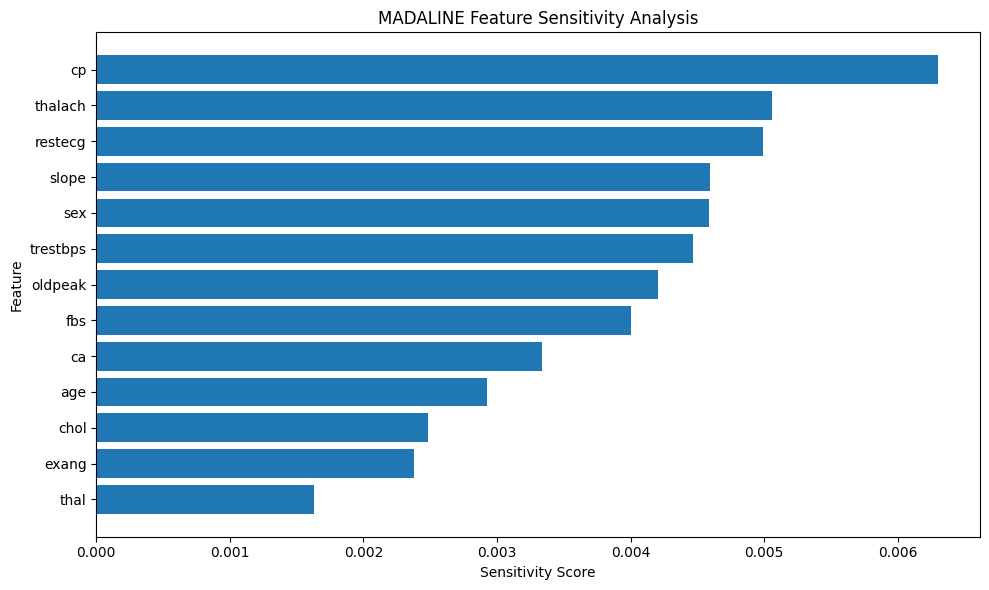


SAMPLE PATIENT PREDICTION

HEART DISEASE PREDICTION

Decision Score: -0.0193
Prediction: No Heart Disease

Note: This is an educational ML prediction, not a medical diagnosis.

FINAL MADALINE SYSTEM SUMMARY

Dataset                : UCI Heart Disease Dataset
Total Samples          : 297
Input Features         : 13
Training Samples       : 237
Testing Samples        : 60
Hidden Neurons         : 8
Initial Learning Rate  : 0.001
Best Learning Rate     : 0.001
Best Accuracy          : 83.33%

Algorithm:
MADALINE (Multiple ADALINE)

Implemented:
1. Heart Disease Classification
2. Adaptive Learning Rate Analysis
3. Decision Score Analysis
4. Low-Confidence Detection
5. Misclassification Analysis
6. Feature Sensitivity Analysis
7. New Patient Prediction


MADALINE-based Heart Disease Classification System completed successfully.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [1]:
# ============================================================
# MADALINE-Based Heart Disease Classification and
# Adaptive Decision Analysis System
# Dataset: UCI Heart Disease Dataset
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. LOAD HEART DISEASE DATASET
# ============================================================

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "target"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

print("=" * 70)
print("MADALINE HEART DISEASE CLASSIFICATION SYSTEM")
print("=" * 70)

print("\nOriginal Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())

# ============================================================
# 2. HANDLE MISSING VALUES
# ============================================================

print("\nMissing Values:")
print(df.isnull().sum())

df = df.dropna().reset_index(drop=True)

print("\nDataset Shape After Removing Missing Values:")
print(df.shape)


# ============================================================
# 3. CONVERT TARGET INTO BINARY CLASS
# ============================================================
# Original UCI target:
# 0 = No Heart Disease
# 1,2,3,4 = Heart Disease
#
# Convert:
# 0 -> 0
# >0 -> 1

df["target"] = np.where(
    df["target"] > 0,
    1,
    0
)

print("\nTarget Distribution:")
print(df["target"].value_counts())

print("\nTarget Meaning:")
print("0 = No Heart Disease")
print("1 = Heart Disease")


# ============================================================
# 4. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop(
    columns=["target"]
)

y = df["target"].values


# ============================================================
# 5. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples :", len(X_test))


# ============================================================
# 6. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(
    X_train
)

X_test = scaler.transform(
    X_test
)


# ============================================================
# 7. MADALINE CLASS
# ============================================================

class MADALINE:

    def __init__(
        self,
        n_features,
        n_hidden=8,
        learning_rate=0.001,
        epochs=100,
        random_state=42
    ):

        self.n_features = n_features
        self.n_hidden = n_hidden
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state

        self.W1 = None
        self.b1 = None

        self.W2 = None
        self.b2 = None

        self.loss_history = []

        self.initialize_weights()


    # --------------------------------------------------------
    # Initialize weights
    # --------------------------------------------------------

    def initialize_weights(self):

        rng = np.random.RandomState(
            self.random_state
        )

        self.W1 = rng.normal(
            0,
            0.1,
            (
                self.n_features,
                self.n_hidden
            )
        )

        self.b1 = np.zeros(
            self.n_hidden
        )

        self.W2 = rng.normal(
            0,
            0.1,
            self.n_hidden
        )

        self.b2 = 0.0


    # --------------------------------------------------------
    # Bipolar activation
    # --------------------------------------------------------

    def activation(self, x):

        return np.where(
            x >= 0,
            1,
            -1
        )


    # --------------------------------------------------------
    # Forward propagation
    # --------------------------------------------------------

    def forward(self, X):

        hidden_input = (
            np.dot(
                X,
                self.W1
            )
            + self.b1
        )

        hidden_output = self.activation(
            hidden_input
        )

        output = (
            np.dot(
                hidden_output,
                self.W2
            )
            + self.b2
        )

        return (
            hidden_input,
            hidden_output,
            output
        )


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    def fit(self, X, y):

        # Convert:
        # 0 -> -1
        # 1 -> +1

        y_binary = np.where(
            y == 1,
            1,
            -1
        )

        self.loss_history = []

        for epoch in range(
            self.epochs
        ):

            total_error = 0

            indices = np.random.permutation(
                len(X)
            )

            X_shuffled = X[indices]
            y_shuffled = y_binary[indices]

            for xi, target in zip(
                X_shuffled,
                y_shuffled
            ):

                # Forward pass

                hidden_input = (
                    np.dot(
                        xi,
                        self.W1
                    )
                    + self.b1
                )

                hidden_output = self.activation(
                    hidden_input
                )

                output = (
                    np.dot(
                        hidden_output,
                        self.W2
                    )
                    + self.b2
                )

                # Calculate error

                error = target - output

                total_error += error ** 2

                # Predicted class

                predicted = (
                    1
                    if output >= 0
                    else -1
                )

                # ------------------------------------------------
                # MADALINE adaptive update
                # ------------------------------------------------

                if predicted != target:

                    # Find neuron closest to decision boundary

                    neuron_index = np.argmin(
                        np.abs(
                            hidden_input
                        )
                    )

                    # Update selected hidden neuron

                    self.W1[:, neuron_index] += (
                        self.learning_rate
                        * error
                        * xi
                    )

                    self.b1[neuron_index] += (
                        self.learning_rate
                        * error
                    )

                    # Update output weight

                    self.W2[neuron_index] += (
                        self.learning_rate
                        * error
                        * hidden_output[
                            neuron_index
                        ]
                    )

                    self.b2 += (
                        self.learning_rate
                        * error
                    )

            mse = (
                total_error
                / len(X)
            )

            self.loss_history.append(
                mse
            )

        return self


    # --------------------------------------------------------
    # Decision score
    # --------------------------------------------------------

    def predict_score(self, X):

        scores = []

        for xi in X:

            _, _, output = self.forward(
                xi.reshape(1, -1)
            )

            scores.append(
                output[0]
            )

        return np.array(
            scores
        )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    def predict(self, X):

        scores = self.predict_score(
            X
        )

        return np.where(
            scores >= 0,
            1,
            0
        )


# ============================================================
# 8. CREATE MADALINE MODEL
# ============================================================

print("\n" + "=" * 70)
print("TRAINING MADALINE NETWORK")
print("=" * 70)

madaline = MADALINE(
    n_features=X_train.shape[1],
    n_hidden=8,
    learning_rate=0.001,
    epochs=100,
    random_state=42
)

madaline.fit(
    X_train,
    y_train
)

print(
    "\nMADALINE training completed successfully."
)


# ============================================================
# 9. PREDICTION
# ============================================================

y_pred = madaline.predict(
    X_test
)


# ============================================================
# 10. ACCURACY
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\n" + "=" * 70)
print("CLASSIFICATION RESULTS")
print("=" * 70)

print(
    f"\nAccuracy: {accuracy * 100:.2f}%"
)


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ]
    )
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "MADALINE Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    [0, 1],
    [
        "No Disease",
        "Disease"
    ]
)

plt.yticks(
    [0, 1],
    [
        "No Disease",
        "Disease"
    ]
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()


# ============================================================
# 13. TRAINING LOSS
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    madaline.loss_history
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Mean Squared Error"
)

plt.title(
    "MADALINE Training Loss"
)

plt.grid(True)

plt.show()


# ============================================================
# 14. ADAPTIVE LEARNING RATE ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("ADAPTIVE LEARNING RATE ANALYSIS")
print("=" * 70)

learning_rates = [
    0.0001,
    0.0005,
    0.001,
    0.005,
    0.01
]

adaptive_results = []

for lr in learning_rates:

    print(
        f"\nTesting Learning Rate: {lr}"
    )

    model = MADALINE(
        n_features=X_train.shape[1],
        n_hidden=8,
        learning_rate=lr,
        epochs=100,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    acc = accuracy_score(
        y_test,
        predictions
    )

    adaptive_results.append({
        "Learning Rate": lr,
        "Accuracy (%)": acc * 100,
        "Final Loss": model.loss_history[-1]
    })


adaptive_df = pd.DataFrame(
    adaptive_results
)

print("\nLearning Rate Results:")
print(
    adaptive_df.to_string(
        index=False
    )
)


# ============================================================
# 15. BEST LEARNING RATE
# ============================================================

best_index = adaptive_df[
    "Accuracy (%)"
].idxmax()

best_learning_rate = adaptive_df.loc[
    best_index,
    "Learning Rate"
]

best_accuracy = adaptive_df.loc[
    best_index,
    "Accuracy (%)"
]

print(
    f"\nBest Learning Rate: "
    f"{best_learning_rate}"
)

print(
    f"Best Accuracy: "
    f"{best_accuracy:.2f}%"
)


# ============================================================
# 16. ADAPTIVE DECISION ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("ADAPTIVE DECISION ANALYSIS")
print("=" * 70)

scores = madaline.predict_score(
    X_test
)

decision_table = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Decision Score": scores
})

decision_table["Actual Label"] = (
    decision_table["Actual"]
    .map({
        0: "No Disease",
        1: "Heart Disease"
    })
)

decision_table["Predicted Label"] = (
    decision_table["Predicted"]
    .map({
        0: "No Disease",
        1: "Heart Disease"
    })
)

print(
    decision_table[
        [
            "Actual Label",
            "Predicted Label",
            "Decision Score"
        ]
    ].head(15)
)


# ============================================================
# 17. DECISION STRENGTH
# ============================================================

decision_table["Decision Strength"] = (
    np.abs(
        decision_table["Decision Score"]
    )
)

print("\nDecision Strength Statistics:")

print(
    decision_table[
        "Decision Strength"
    ].describe()
)


# ============================================================
# 18. LOW-CONFIDENCE SAMPLE DETECTOR
# ============================================================

threshold = np.percentile(
    decision_table["Decision Strength"],
    25
)

low_confidence = decision_table[
    decision_table["Decision Strength"]
    <= threshold
]

print("\n" + "=" * 70)
print("LOW-CONFIDENCE DECISION ANALYSIS")
print("=" * 70)

print(
    f"\nLow-confidence threshold: "
    f"{threshold:.4f}"
)

print(
    f"Low-confidence samples: "
    f"{len(low_confidence)}"
)

print(
    low_confidence[
        [
            "Actual Label",
            "Predicted Label",
            "Decision Score",
            "Decision Strength"
        ]
    ].head(10)
)


# ============================================================
# 19. MISCLASSIFICATION ANALYSIS
# ============================================================

misclassified = decision_table[
    decision_table["Actual"]
    !=
    decision_table["Predicted"]
]

print("\n" + "=" * 70)
print("MISCLASSIFICATION ANALYSIS")
print("=" * 70)

print(
    f"\nTotal Test Samples: {len(y_test)}"
)

print(
    f"Misclassified Samples: "
    f"{len(misclassified)}"
)

print(
    f"Misclassification Rate: "
    f"{len(misclassified) / len(y_test) * 100:.2f}%"
)

if len(misclassified) > 0:

    print("\nMisclassified Samples:")

    print(
        misclassified[
            [
                "Actual Label",
                "Predicted Label",
                "Decision Score"
            ]
        ].head(15)
    )


# ============================================================
# 20. FEATURE SENSITIVITY ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("FEATURE SENSITIVITY ANALYSIS")
print("=" * 70)

feature_importance = np.sum(
    np.abs(
        madaline.W1
        *
        madaline.W2
    ),
    axis=1
)

feature_analysis = pd.DataFrame({
    "Feature": columns[:-1],
    "Sensitivity": feature_importance
})

feature_analysis = feature_analysis.sort_values(
    by="Sensitivity",
    ascending=False
)

print(
    feature_analysis.to_string(
        index=False
    )
)


# ============================================================
# 21. FEATURE SENSITIVITY PLOT
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    feature_analysis["Feature"],
    feature_analysis["Sensitivity"]
)

plt.xlabel(
    "Sensitivity Score"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "MADALINE Feature Sensitivity Analysis"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()


# ============================================================
# 22. NEW PATIENT PREDICTION
# ============================================================

def predict_heart_disease(
    age,
    sex,
    cp,
    trestbps,
    chol,
    fbs,
    restecg,
    thalach,
    exang,
    oldpeak,
    slope,
    ca,
    thal
):

    sample = np.array([
        [
            age,
            sex,
            cp,
            trestbps,
            chol,
            fbs,
            restecg,
            thalach,
            exang,
            oldpeak,
            slope,
            ca,
            thal
        ]
    ])

    sample_scaled = scaler.transform(
        sample
    )

    score = madaline.predict_score(
        sample_scaled
    )[0]

    prediction = (
        1 if score >= 0
        else 0
    )

    print("\n" + "=" * 60)
    print("HEART DISEASE PREDICTION")
    print("=" * 60)

    print(
        "\nDecision Score:",
        round(score, 4)
    )

    if prediction == 1:

        print(
            "Prediction: Heart Disease"
        )

    else:

        print(
            "Prediction: No Heart Disease"
        )

    print(
        "\nNote: This is an educational ML prediction, "
        "not a medical diagnosis."
    )

    return prediction


# ============================================================
# 23. SAMPLE PATIENT
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE PATIENT PREDICTION")
print("=" * 70)

predict_heart_disease(
    age=55,
    sex=1,
    cp=1,
    trestbps=140,
    chol=250,
    fbs=0,
    restecg=1,
    thalach=150,
    exang=0,
    oldpeak=1.0,
    slope=1,
    ca=0,
    thal=2
)


# ============================================================
# 24. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL MADALINE SYSTEM SUMMARY")
print("=" * 70)

print(
    f"""
Dataset                : UCI Heart Disease Dataset
Total Samples          : {len(df)}
Input Features         : {X.shape[1]}
Training Samples       : {len(X_train)}
Testing Samples        : {len(X_test)}
Hidden Neurons         : 8
Initial Learning Rate  : 0.001
Best Learning Rate     : {best_learning_rate}
Best Accuracy          : {best_accuracy:.2f}%

Algorithm:
MADALINE (Multiple ADALINE)

Implemented:
1. Heart Disease Classification
2. Adaptive Learning Rate Analysis
3. Decision Score Analysis
4. Low-Confidence Detection
5. Misclassification Analysis
6. Feature Sensitivity Analysis
7. New Patient Prediction
"""
)

print(
    "\nMADALINE-based Heart Disease Classification "
    "System completed successfully."
)